In [2]:
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_data = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_data = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

print("训练集大小：", len(train_data))
print("测试集大小：", len(test_data))

100.0%
100.0%
100.0%
100.0%

训练集大小： 60000
测试集大小： 10000


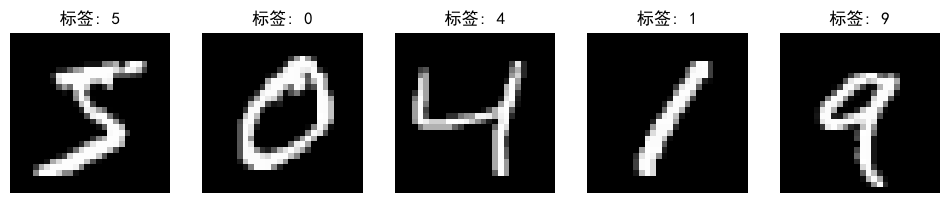

In [8]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    image, label = train_data[i]
    axes[i].imshow(image.squeeze(), cmap="gray")
    axes[i].set_title(f"标签: {label}")
    axes[i].axis("off")
plt.show()

In [9]:
import torch
import torch.nn as nn

class DigitNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(-1, 784)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

model = DigitNet()
print(model)

DigitNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [10]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(3):
    total_loss = 0
    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"第 {epoch+1} 轮，平均损失：{total_loss / len(train_loader):.4f}")

第 1 轮，平均损失：0.3524
第 2 轮，平均损失：0.1634
第 3 轮，平均损失：0.1118


In [11]:
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

correct = 0
total = 0
for images, labels in test_loader:
    outputs = model(images)
    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

print(f"测试集准确率：{correct / total * 100:.2f}%")

测试集准确率：96.76%


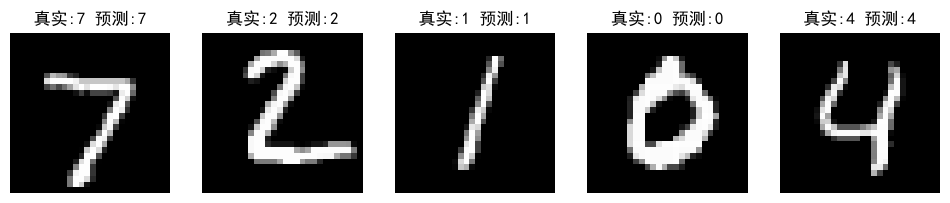

模型已保存


In [12]:
import torch
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    image, label = test_data[i]
    outputs = model(image.unsqueeze(0))
    pred = outputs.argmax(dim=1).item()
    axes[i].imshow(image.squeeze(), cmap="gray")
    axes[i].set_title(f"真实:{label} 预测:{pred}")
    axes[i].axis("off")
plt.show()

torch.save(model.state_dict(), "D:/ml-project3/mnist_model.pth")
print("模型已保存")